## 1. Bayesian Spatial Temporal model

In [ ]:
import pandas as pd
import numpy as np, geopandas as gpd
import rasterstats 
from rasterio import features
from pathlib import Path
import subprocess
import geopandas as gpd
import covasim as cv

import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist

import nutpie
print("nutpie", nutpie.__version__)

import pytensor.tensor as pt
import arviz as az
import pymc as pm

### Explore spatial data; rasters + sewersheds

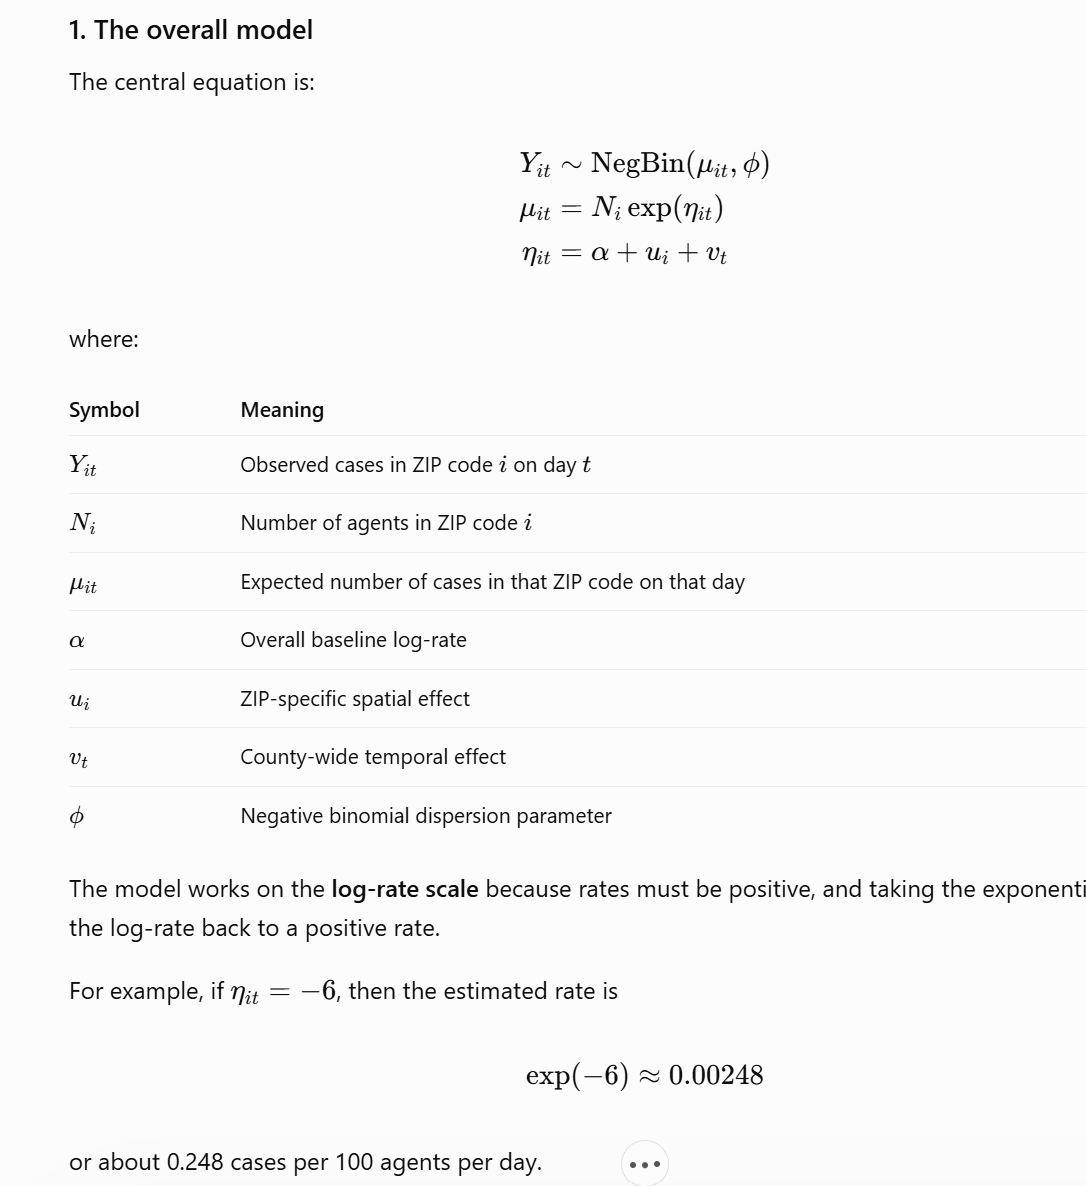

## Population per ZIP from the density raster

The WorldPop raster gives estimated people per ~100 m cell, and the ZIP file gives outlines. They share no
common column, so we match them by **location**: each raster cell is assigned to the ZIP polygon that
contains its centre, and the people in those cells are added up.

Result: a `raster_pop` column on the ZIP table, used as the population denominator for incidence rates.

### Data

In [7]:
REPO_ROOT = Path(subprocess.check_output(["git", "rev-parse", "--show-toplevel"], text=True).strip())
SD_DATA = REPO_ROOT / "docs" / "tutorials" / "san-diego-data"

sewersheds = gpd.read_file(SD_DATA / "sandiego_sewersheds.geojson")

In [8]:
sewersheds.tail()

,sewershed,sid,n_zips,geometry
0,Encina,Encina,18,"POLYGON ((-117.35784 33.1652, -117.35784 33.16..."
1,Point Loma,Point Loma,62,"POLYGON ((-117.28234 32.83273, -117.2823 32.83..."
2,South Bay,South Bay,3,"POLYGON ((-117.13708 32.57957, -117.13589 32.5..."


In [9]:
zips = gpd.read_file(SD_DATA / "sandiego_zip_boundaries.geojson")

In [10]:
zips.head()

,zip,community,sewershed,region_code,region_name,geometry
0,91901,Alpine,Point Loma,91901,Alpine,"POLYGON ((-116.74539 32.96063, -116.74085 32.9..."
1,91902,Bonita,Point Loma,91902,Bonita,"POLYGON ((-116.97172 32.70838, -116.97124 32.7..."
2,91905,Boulevard,None,91905,Boulevard,"POLYGON ((-116.23165 32.75083, -116.22809 32.7..."
3,91906,Campo,None,91906,Campo,"POLYGON ((-116.35677 32.7046, -116.35729 32.70..."
4,91910,Chula Vista,Point Loma,91910,Chula Vista,"POLYGON ((-117.06354 32.65011, -117.06345 32.6..."


In [11]:
import rasterio

with rasterio.open(SD_DATA / "san_diego_county_ppp_2020.tif") as src:
    counts = src.read(1, masked=True)      # the grid of people per cell, nodata masked out
    print(src.crs, src.shape, src.bounds)
    print(f"total pop in raster: {counts.sum():,.0f}")

INFO:rasterio._env:GDAL signalled an error: err_no=1, msg='PROJ: internal_proj_identify: /storage/hcraddock/mamba/envs/covasim/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 5 whereas a number >= 6 is expected. It comes from another PROJ installation.'


GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]] (1189, 1842) BoundingBox(left=-117.60624951449998, bottom=32.524583404130006, right=-116.07124952063998, top=33.515416733500004)
total pop in raster: 3,554,717


## Population per ZIP from the density raster

The WorldPop raster gives estimated people per ~100 m cell, and the ZIP file gives outlines. They share no
common column, so we match them by **location**: each raster cell is assigned to the ZIP polygon that
contains its centre, and the people in those cells are added up.

Result: a `raster_pop` column on the ZIP table, used as the population denominator for incidence rates.

In [13]:
def raster_zonal_sum_verbose(tif, gdf):
    """
    For each polygon (ZIP) in gdf, add up the people in all raster cells whose centre falls inside it.
    The raster and the polygons are matched by LOCATION (longitude/latitude), not by a shared column.
    """
    with rasterio.open(tif) as src:   # open the raster file; `src` holds the grid AND its map position

        # ---------------------------------------------------------------------
        # STEP 1: load the population grid
        # `counts` is a 2D table of numbers. Each entry is one ~100 m square on the map,
        # and the number is the estimated people living in that square.
        # ---------------------------------------------------------------------
        counts = src.read(1, masked=True).filled(0).astype(float)
        #   read(1)         -> take the first (and only) layer of the file
        #   masked=True     -> mark "no data" squares (ocean, outside county) as missing
        #   .filled(0)      -> replace the missing ones with 0 people
        #   .astype(float)  -> use decimal numbers, since people-per-cell are fractions like 4.3
        counts[counts < 0] = 0   # safety: turn any leftover negative placeholder (e.g. -99999) into 0
        print(f"1. grid is {counts.shape[0]} rows x {counts.shape[1]} columns of squares")
        print(f"   total people in the whole grid: {counts.sum():,.0f}")

        # Print a small 5x5 block of real values around the most crowded square,
        # so we can see actual numbers without printing millions of cells.
        r, c = np.unravel_index(counts.argmax(), counts.shape)   # row/column of the biggest value
        r, c = max(r, 2), max(c, 2)                               # keep the block inside the grid edges
        block = (slice(r - 2, r + 3), slice(c - 2, c + 3))        # rows r-2..r+2, columns c-2..c+2
        print("   people in a 5x5 block of squares around the most crowded one:")
        print(counts[block].round().astype(int))

        # ---------------------------------------------------------------------
        # STEP 2: give every ZIP polygon an ID number
        # The raster can only store numbers, so each ZIP needs a number to be painted with.
        # ZIP in row 0 of the table -> 1, row 1 -> 2, ... (0 is kept for "not in any ZIP").
        # to_crs(src.crs) re-expresses the polygon corners in the raster's coordinate system.
        # Without that, the polygons would not line up with the raster.
        # ---------------------------------------------------------------------
        shapes = [(geom, i + 1) for i, geom in enumerate(gdf.to_crs(src.crs).geometry)]
        print(f"\n2. {len(shapes)} polygons, each paired with an ID number")
        print(f"   example: ID {shapes[0][1]} is the polygon for ZIP {gdf.iloc[0]['zip']}")

        # ---------------------------------------------------------------------
        # STEP 3: the actual "join" -- paint each polygon's ID onto a grid
        # This makes a second grid, the same size and position as `counts`.
        # For each square, it checks: is the square's CENTRE point inside a polygon?
        #   yes -> write that polygon's ID in the square
        #   no  -> write 0
        # `src.transform` is the recipe that tells it where each square sits on the map.
        # all_touched=False means only the centre point matters, so each square belongs to
        # at most one ZIP and nothing is counted twice on a border.
        # ---------------------------------------------------------------------
        labels = features.rasterize(iter(shapes), out_shape=counts.shape, transform=src.transform,
                                    fill=0, all_touched=False, dtype='int32')
        print(f"\n3. made an ID grid with the same shape as the people grid: {labels.shape}")
        print(f"   squares inside some ZIP: {(labels > 0).sum():,}   squares in no ZIP: {(labels == 0).sum():,}")
        print("   the same 5x5 block, now showing the ZIP ID of each square (0 = no ZIP):")
        print(labels[block])

    # -------------------------------------------------------------------------
    # STEP 4: add up the people for each ZIP ID
    # We now have two grids lined up square-for-square: people and ZIP IDs.
    # ravel() flattens each grid into one long list so the two lists line up.
    # bincount adds up the people for every distinct ID at once:
    #   sums[0] = total people in squares with ID 0 (outside all ZIPs)
    #   sums[1] = total people in squares with ID 1 (the first ZIP), and so on.
    # minlength makes sure there is a slot for every ZIP, even one that contains no squares.
    # -------------------------------------------------------------------------
    sums = np.bincount(labels.ravel(), weights=counts.ravel(), minlength=len(gdf) + 1)
    print(f"\n4. people outside all ZIPs: {sums[0]:,.0f}")
    print(f"   people in ZIP {gdf.iloc[0]['zip']} (ID 1): {sums[1]:,.0f}")
    # Cross-check using the plain approach: pick only the squares labelled 1 and add them up
    print(f"   cross-check, adding only squares labelled 1: {counts[labels == 1].sum():,.0f}  (should match)")

    # -------------------------------------------------------------------------
    # STEP 5: drop the "outside" slot and hand back one number per ZIP
    # Slot 0 is the outside bucket, so we skip it. What remains is in the same order as the
    # rows of gdf, so you can assign it directly: zips["raster_pop"] = result
    # -------------------------------------------------------------------------
    result = sums[1:]
    print(f"\n5. returning {len(result)} totals, one per ZIP row; first three: {result[:3].round(0)}")
    return result

In [14]:
def raster_zonal_sum(tif, gdf):
    """Sum of raster cells inside each polygon of gdf (same as rasterstats 'sum')."""
    with rasterio.open(tif) as src:
        
        counts = src.read(1, masked=True).filled(0).astype(float)
        counts[counts < 0] = 0                                   # guard against nodata like -99999
        shapes = ((geom, i + 1) for i, geom in enumerate(gdf.to_crs(src.crs).geometry))
        labels = features.rasterize(shapes, out_shape=counts.shape, transform=src.transform,
                                    fill=0, all_touched=False, dtype='int32')
    sums = np.bincount(labels.ravel(), weights=counts.ravel(), minlength=len(gdf) + 1)
    return sums[1:]       

In [15]:
def raster_pop(gdf):
    z = rasterstats.zonal_stats(gdf, tif, stats=['sum'], nodata=-99999, all_touched=False)
    return np.array([s['sum'] or 0 for s in z])

### Create raster population

In [18]:
zips["raster_pop"] = raster_zonal_sum(SD_DATA / "san_diego_county_ppp_2020.tif", zips)

In [19]:
zips[["zip", "community", "sewershed", "raster_pop"]].head()

,zip,community,sewershed,raster_pop
0,91901,Alpine,Point Loma,19154.764128
1,91902,Bonita,Point Loma,18850.564678
2,91905,Boulevard,None,1767.862959
3,91906,Campo,None,3978.341362
4,91910,Chula Vista,Point Loma,83436.326224


In [20]:
print(f"total in ZIPs: {zips['raster_pop'].sum():,.0f}")

total in ZIPs: 3,403,336


## Part 1: Epidemic Simulation

In [21]:
sim = cv.Sim(
    pop_size=100000,
    pop_type='rank',
    pop_infected=50,
    n_days=150,
    n_imports=0,
    rand_seed=1,
    density_raster=str(SD_DATA / 'san_diego_county_ppp_2020.tif'),
    boundary_shapefile=str(SD_DATA / 'sandiego_zip_boundaries.geojson'),
    sewershed_file=str(SD_DATA / 'sandiego_sewersheds.geojson'),
    interventions=[cv.test_prob(symp_prob=0.2, start_day=0)],
    verbose=0,
)
sim.initialize()        # creates the agents and builds the rank network (the slow part)

/storage/hcraddock/GitHub/covasim4wastewater/covasim/population.py:67: RuntimeWarning: 
The boundary file has no "population" column, so regions are weighted by their area. Add a "population" column to weight by population (it is not needed when pop_type="rank" uses a density_raster).
  cvm.warn(


Sim(<no label>; 2020-03-01 to 2020-07-29; pop: 100000 rank; epi: not run)

In [22]:
sim.run()

Sim(<no label>; 2020-03-01 to 2020-07-29; pop: 100000 rank; epi: 77048⚙, 475☠)

In [24]:
people = sim.people
print("infected:", int((~np.isnan(people.date_exposed)).sum()))
print("diagnosed:", int((~np.isnan(people.date_diagnosed)).sum()))

infected: 68492
diagnosed: 37438


## Cases per zip

In [25]:
people = sim.people
T = sim.npts                                    # number of days in the run

# Which row of the zips table each agent belongs to (people.region holds the ZIP code)
zip_row = {code: i for i, code in enumerate(zips["region_code"].astype(int))}
agent_row = np.array([zip_row[c] for c in people.region])

# Only agents who were ever diagnosed have a diagnosis date; the rest are NaN
diag = ~np.isnan(people.date_diagnosed)
days = people.date_diagnosed[diag].astype(int)

# cases[i, t] = number of people diagnosed in ZIP i on day t
cases = np.zeros((len(zips), T), dtype=int)
np.add.at(cases, (agent_row[diag], days), 1)   # add 1 to the right cell for each diagnosed agent

print("table shape (ZIPs, days):", cases.shape)
print("total cases in table:", cases.sum(), "  (should be 4516)")
print("cases in the first 5 ZIPs, first 10 days:")
print(cases[:5, :10])

table shape (ZIPs, days): (113, 151)
total cases in table: 37438   (should be 4516)
cases in the first 5 ZIPs, first 10 days:
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]


In [43]:
cases_df = pd.DataFrame(cases, index=zips["region_code"].astype(int), columns=np.arange(T))

In [44]:
cases_df.head()

,0,1,2,3,4,5,6,7,8,9,...,141,142,143,144,145,146,147,148,149,150
region_code,,,,,,,,,,,,,,,,,,,,,
91901,0,0,0,0,0,0,0,0,0,0,...,0,0,3,1,1,0,0,0,0,0
91902,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
91905,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
91906,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
91910,0,0,0,0,0,0,0,0,0,0,...,1,0,1,0,1,1,1,1,0,0


agents per ZIP: min 0  median 846  max 2791
ZIPs with fewer than 50 agents: 20 of 113
ZIPs with 0 cases all run: 2


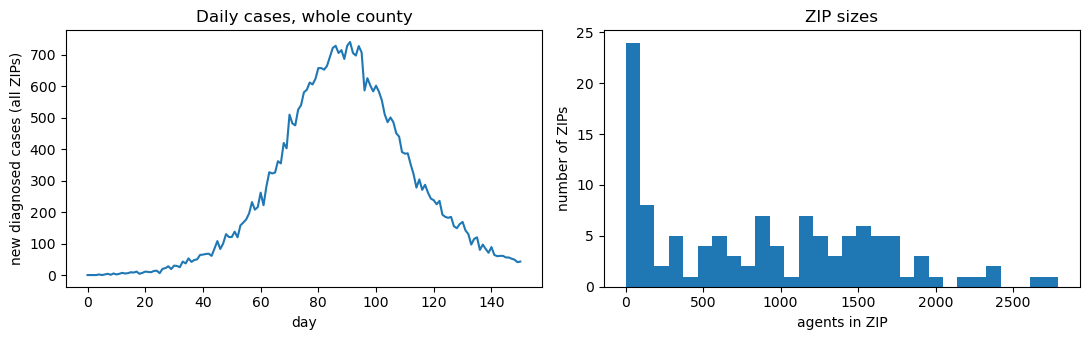

In [26]:
import matplotlib.pyplot as plt

# N[i] = number of simulated agents living in ZIP i (the denominator for the rate)
N = np.bincount(agent_row, minlength=len(zips))

print("agents per ZIP: min", N.min(), " median", int(np.median(N)), " max", N.max())
print("ZIPs with fewer than 50 agents:", (N < 50).sum(), "of", len(N))
print("ZIPs with 0 cases all run:", (cases.sum(axis=1) == 0).sum())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(cases.sum(axis=0))
ax[0].set_xlabel("day"); ax[0].set_ylabel("new diagnosed cases (all ZIPs)")
ax[0].set_title("Daily cases, whole county")
ax[1].hist(N, bins=30)
ax[1].set_xlabel("agents in ZIP"); ax[1].set_ylabel("number of ZIPs")
ax[1].set_title("ZIP sizes")
plt.tight_layout(); plt.show()

## Plot weekly

agents per ZIP: min 0  median 846  max 2791
ZIPs with fewer than 50 agents: 20 of 113
ZIPs with 0 cases all run: 2
weekly table shape (ZIPs, weeks): (113, 21)  (dropped 4 leftover days)


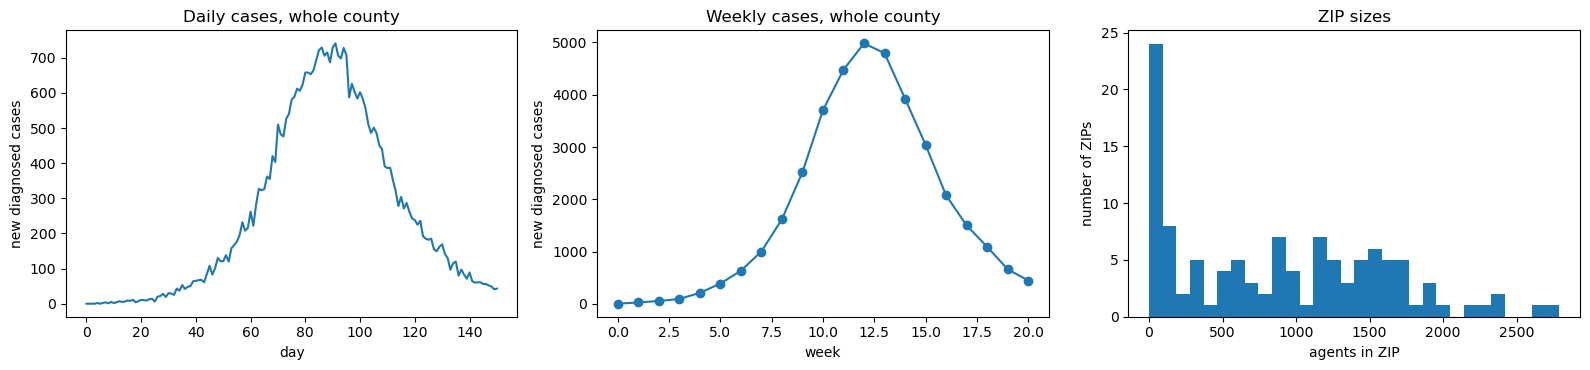

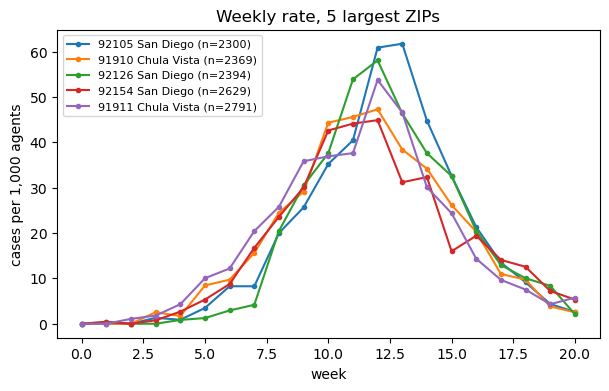

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# N[i] = number of simulated agents living in ZIP i (the denominator for the rate)
N = np.bincount(agent_row, minlength=len(zips))

print("agents per ZIP: min", N.min(), " median", int(np.median(N)), " max", N.max())
print("ZIPs with fewer than 50 agents:", (N < 50).sum(), "of", len(N))
print("ZIPs with 0 cases all run:", (cases.sum(axis=1) == 0).sum())

# Weekly cases: drop leftover days so the total divides evenly by 7,
# then reshape to (ZIPs, weeks, 7 days) and add up the 7 days in each week
n_weeks = cases.shape[1] // 7
weekly = cases[:, :n_weeks * 7].reshape(len(zips), n_weeks, 7).sum(axis=2)    # shape (ZIPs, weeks)
print(f"weekly table shape (ZIPs, weeks): {weekly.shape}  (dropped {cases.shape[1] - n_weeks*7} leftover days)")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))

# Left: daily cases, whole county
ax[0].plot(cases.sum(axis=0))
ax[0].set_xlabel("day"); ax[0].set_ylabel("new diagnosed cases")
ax[0].set_title("Daily cases, whole county")

# Middle: weekly cases, whole county (line with a dot for each week)
ax[1].plot(np.arange(n_weeks), weekly.sum(axis=0), marker="o")
ax[1].set_xlabel("week"); ax[1].set_ylabel("new diagnosed cases")
ax[1].set_title("Weekly cases, whole county")

# Right: ZIP sizes
ax[2].hist(N, bins=30)
ax[2].set_xlabel("agents in ZIP"); ax[2].set_ylabel("number of ZIPs")
ax[2].set_title("ZIP sizes")

plt.tight_layout(); plt.show()

# Weekly rate for the 5 largest ZIPs, one line per ZIP
big = np.argsort(N)[-5:]
plt.figure(figsize=(7, 4))
for i in big:
   plt.plot(weekly[i] / N[i] * 1000, marker="o", ms=3, label=f"{zips.loc[i, 'zip']} {zips.loc[i, 'community']} (n={N[i]})")
plt.xlabel("week");
plt.ylabel("cases per 1,000 agents")
plt.title("Weekly rate, 5 largest ZIPs"); plt.legend(fontsize=8)
plt.show()

## Bayesian Spatial Model setup

#### i. Create Adjacency Matrix - Define neighbouring ZIPs

In [28]:
# Neighbours: two ZIPs are neighbours if their outlines touch (tiny buffer closes hairline gaps)
#i. Grow each ZIP outline by ~10 cm so near-touching borders overlap
zip_shapes = zips.geometry.buffer(1e-6)                    
# ii. Fast lookup of which shapes are nearby (avoids comparing every pair)
shape_index = zip_shapes.sindex
#Setup matrix of False: adjacency[i, j] = does ZIP i touch ZIP j?                             
adjacency = np.zeros((len(zips), len(zips)), dtype=bool)     # table of False: adjacency[i, j] = does ZIP i touch ZIP j?

for i, shape in enumerate(zip_shapes):                       # take each ZIP in turn (i = row number, shape = its outline)
    
    #NB!! Row numbers of every ZIP whose outline overlaps this one
    for j in shape_index.query(shape, predicate="intersects"):   
        if j != i:                                           # skip the ZIP itself (it always overlaps itself)
            adjacency[i, j] = True                           # mark ZIP i and ZIP j as neighbours
adjacency = adjacency | adjacency.T                          # make it symmetric: if i touches j, then j touches i

/tmp/ipykernel_610012/2575535216.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  zip_shapes = zips.geometry.buffer(1e-6)


#### Neighbours

In [29]:
zips['community'].value_counts().head(5)

community
San Diego      36
Chula Vista     5
Carlsbad        4
Escondido       4
El Cajon        3
Name: count, dtype: int64

In [62]:
zips.head()

,zip,community,sewershed,region_code,region_name,geometry,raster_pop
0,91901,Alpine,Point Loma,91901,Alpine,"POLYGON ((-116.74539 32.96063, -116.74085 32.9...",19154.764128
1,91902,Bonita,Point Loma,91902,Bonita,"POLYGON ((-116.97172 32.70838, -116.97124 32.7...",18850.564678
2,91905,Boulevard,None,91905,Boulevard,"POLYGON ((-116.23165 32.75083, -116.22809 32.7...",1767.862959
3,91906,Campo,None,91906,Campo,"POLYGON ((-116.35677 32.7046, -116.35729 32.70...",3978.341362
4,91910,Chula Vista,Point Loma,91910,Chula Vista,"POLYGON ((-117.06354 32.65011, -117.06345 32.6...",83436.326224


### ii. Join islands

In [30]:
# Join any islands to the main map by linking them to the nearest ZIP (by centroid)
centroids = np.column_stack([zips.geometry.centroid.x, zips.geometry.centroid.y])
n_pieces, piece_of_zip = connected_components(sp.csr_matrix(adjacency), directed=False)
print("separate pieces before joining:", n_pieces)
while n_pieces > 1:
    in_main_piece = piece_of_zip == np.argmax(np.bincount(piece_of_zip))
    distances = cdist(centroids[~in_main_piece], centroids[in_main_piece])
    row, col = np.unravel_index(distances.argmin(), distances.shape)
    island_zip = np.flatnonzero(~in_main_piece)[row]
    main_zip = np.flatnonzero(in_main_piece)[col]
    print(f"linking {zips.loc[island_zip, 'community']} -> {zips.loc[main_zip, 'community']}")
    adjacency[island_zip, main_zip] = adjacency[main_zip, island_zip] = True
    n_pieces, piece_of_zip = connected_components(sp.csr_matrix(adjacency), directed=False)

separate pieces before joining: 1


/tmp/ipykernel_610012/490780746.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = np.column_stack([zips.geometry.centroid.x, zips.geometry.centroid.y])


### iii. Cases

In [31]:
# Which ZIPs have data? (ZIPs with 0 agents stay in the map but have no likelihood)
zip_has_agents = N > 0
zips_with_data = np.flatnonzero(zip_has_agents)
print(f"ZIPs total: {len(zips)}   with agents: {zip_has_agents.sum()}   with 0 agents: {(~zip_has_agents).sum()}")

agents_in_zip = N[zips_with_data].astype(float)     # offset N_i, only ZIPs with agents
cases_observed = cases[zips_with_data]              # observed cases y_it, only ZIPs with agents
n_zips = len(zips)                                  # ALL ZIPs (the spatial effect covers every ZIP)
n_days = cases.shape[1]

# Each touching pair of ZIPs listed once: ZIP neighbour_a[k] touches ZIP neighbour_b[k]
neighbour_a, neighbour_b = np.where(np.triu(adjacency, 1))
print(f"{len(neighbour_a)} neighbour pairs, average neighbours per ZIP {adjacency.sum(1).mean():.1f}")

ZIPs total: 113   with agents: 112   with 0 agents: 1
299 neighbour pairs, average neighbours per ZIP 5.3


## Part 2: Bayesian Model

##### Toy example

In [87]:
import numpy as np
adj = np.array([[0,1,0],[1,0,1],[0,1,0]], float)
Q = np.diag(adj.sum(1)) - adj          # [[ 1,-1, 0],[-1, 2,-1],[ 0,-1, 1]]
print(np.diag(np.linalg.pinv(Q)))      # variances: the end ZIPs are larger than the middle one

[0.55555556 0.22222222 0.55555556]


In [88]:
Q = np.diag(adjacency.sum(1)) - adjacency.astype(float)

print("shape:", Q.shape)
print("share of entries that are exactly zero:", (Q == 0).mean().round(3))      # should be around 0.95

i = 0
print("ZIP", zips.loc[i, "zip"], "row has", (Q[i] != 0).sum(), "non-zero entries")   # 1 diagonal + its neighbours
print("diagonal:", Q[i, i], "  the -1 entries are in columns:", np.flatnonzero(Q[i] == -1))
print("row sums (should all be 0):", np.unique(Q.sum(axis=1)))

shape: (113, 113)
share of entries that are exactly zero: 0.944
ZIP 91901 row has 12 non-zero entries
diagonal: 11.0   the -1 entries are in columns: [ 3  9 10 14 20 21 33 35 42 44 54]
row sums (should all be 0): [0.]


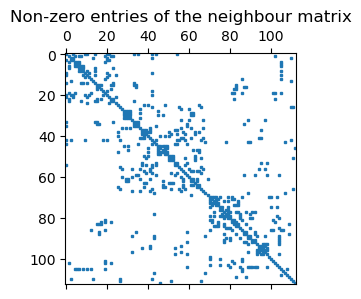

In [95]:
import matplotlib.pyplot as plt
plt.figure(figsize=(3, 3))
plt.spy(Q, markersize=2)
plt.title("Non-zero entries of the neighbour matrix"); plt.show()

### iv. Spatial components

In [94]:
aa = np.diag(adjacency.sum(1))

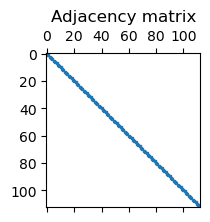

In [96]:
## Plot adjancey
plt.figure(figsize=(2, 2))
plt.spy(aa, markersize=2)
plt.title("Adjacency matrix"); plt.show()

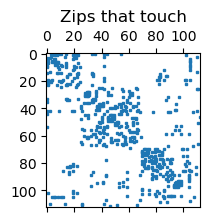

In [98]:
bb = adjacency.astype(float)
#Plot
## Plot adjancey
plt.figure(figsize=(2, 2))
plt.spy(bb, markersize=2)
plt.title("Zips that touch"); plt.show()

In [86]:
np.diag(adjacency.sum(1)) - adjacency.astype(float)

array([[11.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  7.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  5., ..., -1.,  0.,  0.],
       ...,
       [ 0.,  0., -1., ...,  4.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  3.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  1.]])

<img src="attachment:image.png" width="400">

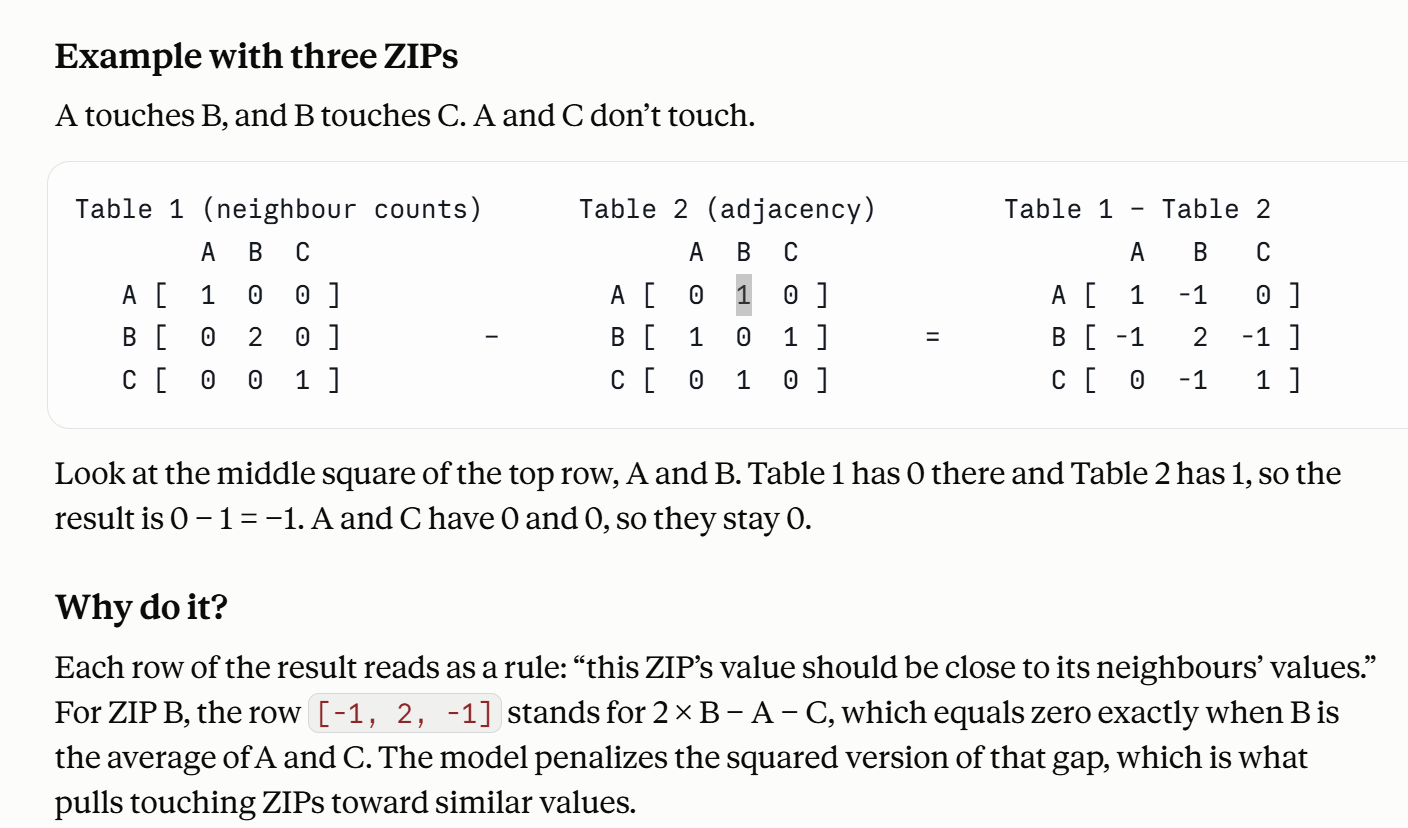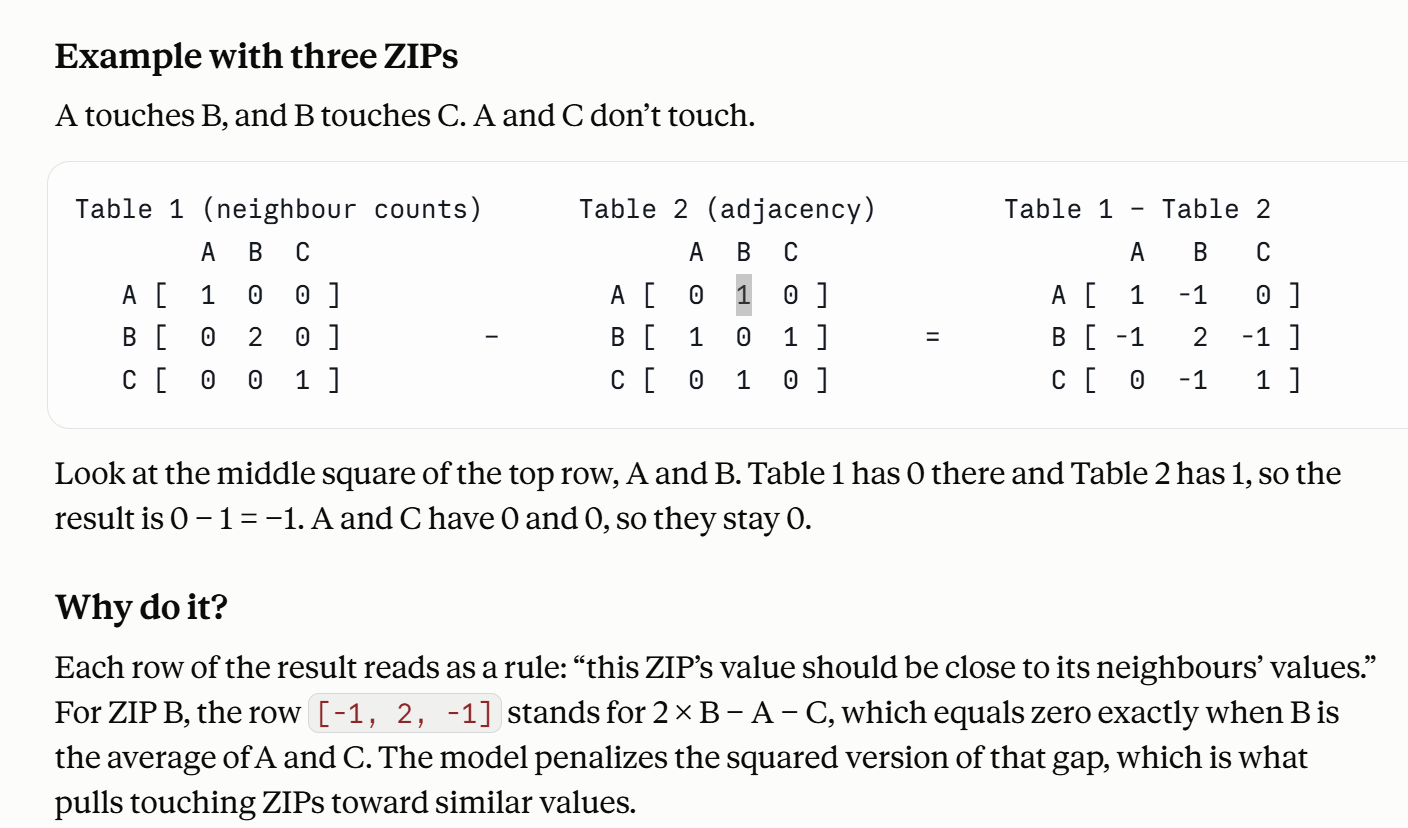width=400

## Part II Determining priors

In [32]:
total_cases = cases_observed.sum()
print(f"total_cases: {total_cases:.5f}")
agent_days = agents_in_zip.sum() * n_days
print(f"agent_days: {agent_days:.5f}")
average_rate = total_cases / agent_days
print(f"average diagnosed rate: {average_rate:.5f} per agent per day")
print(f"log of that: {np.log(average_rate):.2f}")

total_cases: 37438.00000
agent_days: 15100000.00000
average diagnosed rate: 0.00248 per agent per day
log of that: -6.00


### Rho prior

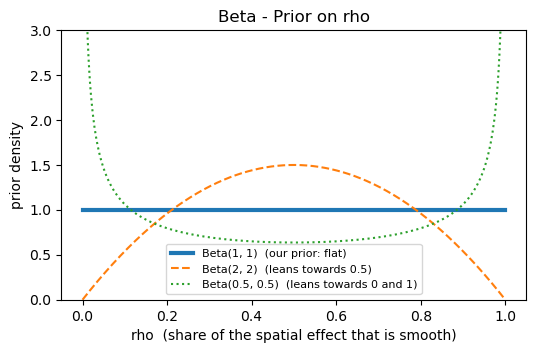

In [103]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

x = np.linspace(0, 1, 500)

plt.figure(figsize=(6, 3.5))
plt.plot(x, beta.pdf(x, 1, 1), lw=3, label="Beta(1, 1)  (our prior: flat)")
plt.plot(x, beta.pdf(x, 2, 2), ls="--", label="Beta(2, 2)  (leans towards 0.5)")
plt.plot(x, beta.pdf(x, 0.5, 0.5), ls=":", label="Beta(0.5, 0.5)  (leans towards 0 and 1)")
plt.xlabel("rho  (share of the spatial effect that is smooth)")
plt.ylabel("prior density")
plt.title("Beta - Prior on rho")
plt.ylim(0, 3)
plt.legend(fontsize=8)
plt.show()

## Part 2: Bayesian Spatial Model

In [33]:
# BYM2 scaling factor
# The spatial effect has a "smooth" part (neighbouring ZIPs look alike) and an "independent" part (random noise per ZIP).
# Before mixing them with weight rho, both need the same typical size (variance about 1);
# otherwise rho would not mean "share of the spatial effect that is smooth".
# This block measures how big the smooth part naturally is on our ZIP map, so the model can divide it out.

# Neighbour-rule table: diagonal = number of neighbours of each ZIP, -1 wherever two ZIPs touch, 0 elsewhere.
# Each row says "this ZIP should be close to the average of its neighbours".
icar_precision = np.diag(adjacency.sum(1)) - adjacency.astype(float)

# Step by step, from the inside out:
#   np.linalg.pinv(...)  invert the table to get how much each ZIP's smooth effect varies (a pseudo-inverse,
#                        because the neighbour rule alone does not fix the overall level)
#   np.diag(...)         keep only the diagonal: one variance per ZIP (ZIPs with many neighbours vary less)
#   np.log, np.mean      average those variances on the log scale
#   np.exp               convert back: this is the geometric mean, one typical variance for the whole map
bym2_scale = float(np.exp(np.mean(np.log(np.diag(np.linalg.pinv(icar_precision))))))

# The model later divides the smooth part by this number, so it ends up with variance about 1
print("BYM2 scaling factor =", round(bym2_scale, 3))   # a plain positive number; nan or inf means a ZIP has no neighbours

BYM2 scaling factor = 0.406


## i. Model for daily cases

In [ ]:
with pm.Model() as model:
    # A line like  x = pm.Normal("x", mean, sd)  means: "x is unknown; before seeing data, we think it is
    # probably near `mean`, give or take `sd`". That starting belief is called a PRIOR. The data then update it.

    # ---- INTERCEPT (Baseline model) -----------------------------------------------------------------
    # alpha = Intercept. the average log-rate: log of (cases per agent per day) for a typical ZIP on a typical day.
    # Prior: mean -6, sd 3. exp(-6) = 0.0025, i.e. about 0.25% of agents per day; sd 3 keeps it very open.
    # Without the spatial and daily effects, the model would be log(rate) = alpha.
    alpha = pm.Normal("alpha", -6.0, 3.0)

    # ---- Spatial effect u_i: how much higher or lower than average is ZIP i? (BYM2) ---------
    # sigma_u = STANDARD DEVIATION of u across ZIPs = typical size of ZIP-to-ZIP differences in log-rate.
    # sigma_u = 0.5 would mean ZIPs differ by about a factor of e^0.5 = 1.6 up or down.
    # HalfNormal because a standard deviation cannot be negative (explained below).
    sigma_u = pm.HalfNormal("sigma_u", 1.0)

    # rho = fraction (0 to 1) of the spatial effect that is smooth across neighbours.
    # 0 = pure per-ZIP noise, 1 = fully smooth map. Beta(1, 1) is flat: all values equally likely beforehand.
    rho = pm.Beta("rho", 1, 1)

    # u_smooth = the smooth part: one value per ZIP, forced to average exactly 0.
    # sigma=5 is only a loose bound; the smoothness itself comes from the penalty on the next line.
    u_smooth = pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips)

    # ICAR penalty: adds -0.5 * (difference)^2 for every pair of touching ZIPs, so values where
    # neighbours differ a lot become less likely. This is what makes u_smooth "smooth".
    pm.Potential("icar", -0.5 * pt.sum((u_smooth[neighbour_a] - u_smooth[neighbour_b]) ** 2))

    # u_independent = the noise part: one standard-normal value per ZIP, unrelated to neighbours.
    u_independent = pm.Normal("u_independent", 0, 1, shape=n_zips)

    #FINAL SPATIAL EFFECT: u = sigma_u * (sqrt(rho / bym2_scale) * u_smooth + sqrt(1 - rho) * u_independent)
    # u = the final spatial effect per ZIP: a mix of the smooth and noise parts (weights rho and 1-rho),
    # rescaled by bym2_scale so both parts have variance about 1, then multiplied by sigma_u.
    u = pm.Deterministic("u", sigma_u * (pt.sqrt(rho / bym2_scale) * u_smooth + pt.sqrt(1 - rho) * u_independent))

    
    # ---- Temporal effect v_t: how much higher or lower than average is the whole county on day t? ----
    # sigma_v = STANDARD DEVIATION of one day's change in log-rate (v_t minus v_{t-1}).
    # sigma_v = 0.1 would mean the rate typically moves about 10% from one day to the next.
    sigma_v = pm.HalfNormal("sigma_v", 0.5)

    # daily_steps = one standard-normal random number per day (the "shocks"); scaled by sigma_v next line
    daily_steps = pm.Normal("daily_steps", 0, 1, shape=n_days)

    # v_walk = random walk: running total of the scaled daily steps, so today = yesterday + a random step.
    v_walk = sigma_v * pt.cumsum(daily_steps)

    # v = the walk shifted to average 0, so the overall level is carried by alpha alone (keeps them identifiable).
    v = pm.Deterministic("v", v_walk - v_walk.mean())

    # ---- Combine: the log-rate for every ZIP and day -----------------------------------
    # eta[i, t] = alpha + u_i + v_t   (eta is the log of the per-agent case rate; your slide's eta_it)
    # Only ZIPs that have agents are used; the [:, None] / [None, :] reshape lines the pieces into a ZIPs x days grid.
    eta = alpha + u[zips_with_data][:, None] + v[None, :]

    # ---- Observation: how observed counts arise from the rate --------------------------
    # dispersion = how much the counts scatter beyond pure Poisson randomness.
    # The negative-binomial variance is  mean + mean^2 / dispersion, so a SMALL dispersion = very noisy counts,
    # and a LARGE one = close to Poisson. Exponential(0.1) has an average of 10 and must be positive.
    dispersion = pm.Exponential("dispersion", 0.1)

    # Expected cases in ZIP i on day t = agents_in_zip[i] * exp(eta[i, t]). The observed table is then treated
    # as noisy draws around that expectation. (In PyMC's function, `alpha=` is the dispersion argument;
    # it has nothing to do with our baseline alpha above.)
    pm.NegativeBinomial("cases", mu=pt.exp(eta + np.log(agents_in_zip)[:, None]),
                        alpha=dispersion, observed=cases_observed)

    # ---- Fit: draw samples of every unknown that are consistent with the data ----------
    # tune = warm-up draws thrown away; draws = draws kept; chains = independent runs (they should agree);
    # target_accept = higher means smaller, more careful steps (fewer divergences, slower).
    idata = pm.sample(draws=500, tune=500, chains=2, target_accept=0.9, random_seed=1)

print(az.summary(idata, var_names=["alpha", "sigma_u", "rho", "sigma_v", "dispersion"]))   # r_hat near 1.00 = chains agree
print("divergences:", int(idata.sample_stats["diverging"].sum()))                           # 0 or very few is good

INFO:pymc.sampling.mcmc:Initializing NUTS using jitter+adapt_diag...
INFO:/storage/hcraddock/mamba/envs/covasim/lib/python3.10/site-packages/pytensor/link/c/lazylinker_c.py:Compiling new CVM
INFO:/storage/hcraddock/mamba/envs/covasim/lib/python3.10/site-packages/pytensor/link/c/lazylinker_c.py:New version 0.31
INFO:pymc.sampling.mcmc:Multiprocess sampling (2 chains in 2 jobs)
INFO:pymc.sampling.mcmc:NUTS: [alpha, sigma_u, rho, u_smooth, u_independent, sigma_v, daily_steps, dispersion]


Output()

In [ ]:
#Posterior outputs: the draws of every unknown parameter, after seeing the data. The shape is (chains, draws, unknowns).b
rng = np.random.default_rng(0)

posterior = idata.posterior
n_samples = posterior.sizes["chain"] * posterior.sizes["draw"]
alpha_draws = posterior["alpha"].values.reshape(n_samples)
u_draws = posterior["u"].values.reshape(n_samples, n_zips)
v_draws = posterior["v"].values.reshape(n_samples, n_days)
dispersion_draws = posterior["dispersion"].values.reshape(n_samples)

## ii. Model for weekly cases

In [35]:
# Weekly cases: add up each block of 7 days; leftover days at the end are dropped
n_weeks = cases.shape[1] // 7
cases_weekly_all = cases[:, :n_weeks * 7].reshape(len(zips), n_weeks, 7).sum(axis=2)    # (ZIPs, weeks)
cases_observed = cases_weekly_all[zips_with_data]                                       # only ZIPs that have agents

average_weekly_rate = cases_observed.sum() / (agents_in_zip.sum() * n_weeks)            # cases per agent per week, whole run
log_average_weekly_rate = float(np.log(average_weekly_rate))
print(n_weeks, "weeks;", cases_observed.shape, "table; log average weekly rate =", round(log_average_weekly_rate, 2))

21 weeks; (112, 21) table; log average weekly rate = -4.03


In [ ]:
with pm.Model() as model:
    # A line like x = pm.Normal("x", mean, sd) means: "x is unknown; before seeing data, we think it is
    # probably near `mean`, give or take `sd`". This starting belief is called a PRIOR; data update it.

    # ---- INTERCEPT (Baseline model) -----------------------------------------------------------------
    # alpha = average log-rate (cases per agent per WEEK) for a typical ZIP in a typical week.
    # Prior is centred on the observed average weekly log-rate; sd=2 allows substantial uncertainty.
    # Without spatial and weekly effects, log(rate) = alpha.
    alpha = pm.Normal("alpha", log_average_weekly_rate, 2.0)

    # ---- Spatial effect u_i: how much higher or lower than average is ZIP i? (BYM2) -----------------
    # sigma_u = standard deviation of ZIP-level differences on the log-rate scale.
    #pm.HalfNormal("sigma_u", 1.0): 1.0 is the scale (standard deviation) of the prior for sigma_u, not a fixed value.
    # A HalfNormal distribution is centred at zero and only allows positive values, so it needs just one parameter: its scale, which controls how spread out the values are.
    # For example, sigma_u=0.5 corresponds to a rate ratio of exp(0.5) ≈ 1.6; HalfNormal ensures it is positive.
    sigma_u = pm.HalfNormal("sigma_u", 1.0)

    # rho = proportion of spatial variation attributed to the smooth component: 0 = none, 1 = all.
    # Beta(1, 1) is uniform on [0, 1], so all values are equally likely a priori.
    rho = pm.Beta("rho", 1, 1)

    # u_smooth = one spatial effect per ZIP, constrained to sum to zero.
    # sigma=5 sets the scale of its base prior; the neighbour penalty below encourages smoothness.
    #pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips): 5.0 is the prior standard deviation, and shape=n_zips creates one spatial effect per ZIP, constrained to sum to zero across ZIPs.
    u_smooth = pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips)

    # ICAR-style penalty: subtracts 0.5 × squared difference for each pair of neighbouring ZIPs.
    # Larger neighbour differences receive a stronger penalty, encouraging similar effects.
    pm.Potential("icar", -0.5 * pt.sum((u_smooth[neighbour_a] - u_smooth[neighbour_b]) ** 2))

    # u_independent = one independent standard Normal effect per ZIP (mean=0, sd=1).
    # These effects are not smoothed across neighbouring ZIPs.
    #pm.Normal("u_independent", 0, 1, shape=n_zips): 0 is the prior mean and 1 the prior standard deviation; each ZIP gets its own independent draw, so the prior is the same for every ZIP, but the sampled effects can differ.
    u_independent = pm.Normal("u_independent", 0, 1, shape=n_zips)

    # Combine the smooth and independent components, then scale by sigma_u.
    # rho and 1-rho weight the components; bym2_scale adjusts the scale of the smooth component.
    u = pm.Deterministic(
        "u",
        sigma_u * (
            pt.sqrt(rho / bym2_scale) * u_smooth
            + pt.sqrt(1 - rho) * u_independent
        )
    )

    # ---- Temporal effect v_w: how much higher or lower than average is the county in week w? ----------
    # sigma_v = standard deviation of weekly changes in log-rate; HalfNormal(1.0) allows substantial changes.
    # A change of 0.5 on the log scale corresponds to a rate multiplier of exp(0.5) ≈ 1.6.
    sigma_v = pm.HalfNormal("sigma_v", 1.0)

    # One standard Normal shock per week (mean=0, sd=1); n_weeks is the number of weekly observations.
    weekly_steps = pm.Normal("weekly_steps", 0, 1, shape=n_weeks)

    # Random walk: cumulatively add the weekly shocks, scaled by sigma_v.
    v_walk = sigma_v * pt.cumsum(weekly_steps)

    # Centre the weekly effects at zero so alpha represents the overall baseline log-rate.
    v = pm.Deterministic("v", v_walk - v_walk.mean())

    # ---- Combine: the log-rate for every ZIP and week -----------------------------------------------
    # eta[i, w] = alpha + u_i + v_w; broadcasting creates a ZIPs × weeks grid.
    eta = alpha + u[zips_with_data][:, None] + v[None, :]

    # ---- Observation: how observed counts arise from the rate ---------------------------------------
    # dispersion controls extra-Poisson variation: variance = mean + mean² / dispersion.
    # Exponential(0.1) has rate=0.1 and prior mean=1/0.1=10; the estimated dispersion must be positive.
    dispersion = pm.Exponential("dispersion", 0.1)

    # Expected cases = agents in ZIP × exp(eta); observed counts vary around this expectation.
    # PyMC's `alpha=` is the negative-binomial dispersion parameter, unrelated to the baseline alpha above.
    pm.NegativeBinomial(
        "cases",
        mu=pt.exp(eta + np.log(agents_in_zip)[:, None]),
        alpha=dispersion,
        observed=cases_observed
    )

    # ---- Fit: draw samples from the posterior distributions -----------------------------------------
    # tune=1000 warm-up iterations; draws=1000 retained draws per chain; chains=4 independent runs.
    # target_accept=0.9 requests more conservative NUTS steps; nutpie selects the sampler implementation.
    idata = pm.sample(
        draws=1000, tune=1000, chains=4, target_accept=0.9,
        random_seed=1, nuts_sampler="nutpie", progressbar=False
    )

# R-hat near 1.00 suggests chains agree; also check effective sample sizes and intervals.
print(az.summary(idata, var_names=["alpha", "sigma_u", "rho", "sigma_v", "dispersion"]))

# Divergences should ideally be zero or very few.
print("divergences:", int(idata.sample_stats["diverging"].sum()))

              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
alpha       -4.942  0.023  -4.987   -4.900      0.001    0.000    1025.0   
sigma_u      0.032  0.015   0.001    0.057      0.001    0.000     558.0   
rho          0.670  0.256   0.195    0.999      0.007    0.004    1466.0   
sigma_v      0.580  0.115   0.382    0.803      0.018    0.011      47.0   
dispersion  27.080  2.610  22.409   32.092      0.030    0.049    7800.0   

            ess_tail  r_hat  
alpha         1769.0   1.01  
sigma_u        571.0   1.00  
rho           1883.0   1.00  
sigma_v         69.0   1.07  
dispersion    2570.0   1.00  
divergences: 0


### Posterior output

In [38]:
rng = np.random.default_rng(0)

posterior = idata.posterior
n_samples = posterior.sizes["chain"] * posterior.sizes["draw"]
alpha_draws = posterior["alpha"].values.reshape(n_samples)
u_draws = posterior["u"].values.reshape(n_samples, n_zips)
v_draws = posterior["v"].values.reshape(n_samples, n_weeks)                  # CHANGED: n_weeks
dispersion_draws = posterior["dispersion"].values.reshape(n_samples)

95% interval covers 96.0% of observed ZIP-week counts (aim: about 95%)


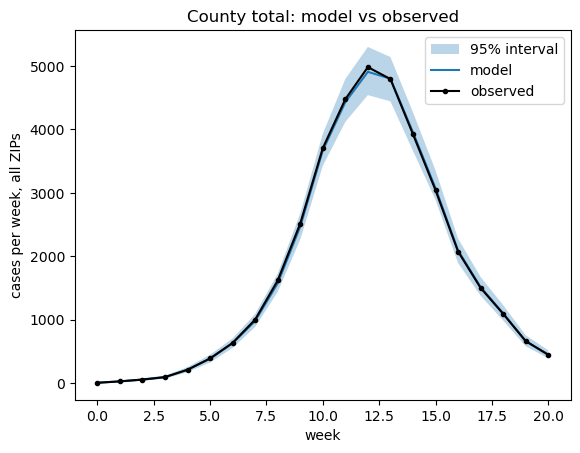

In [39]:
# Simulate weekly case counts from the fitted model, using a random 300 of the posterior draws
chosen = rng.choice(n_samples, size=min(300, n_samples), replace=False)
expected_cases = agents_in_zip[None, :, None] * np.exp(
    alpha_draws[chosen, None, None] + u_draws[chosen][:, zips_with_data, None] + v_draws[chosen, None, :])
k = dispersion_draws[chosen][:, None, None]
cases_simulated = rng.poisson(rng.gamma(k, expected_cases / k))              # (draws, ZIPs, weeks)

low, high = np.percentile(cases_simulated, [2.5, 97.5], axis=0)
print(f"95% interval covers {((cases_observed >= low) & (cases_observed <= high)).mean():.1%} of observed ZIP-week counts (aim: about 95%)")

total_low, total_mid, total_high = np.percentile(cases_simulated.sum(1), [2.5, 50, 97.5], axis=0)
plt.fill_between(range(n_weeks), total_low, total_high, alpha=0.3, label="95% interval")
plt.plot(total_mid, label="model"); plt.plot(cases_observed.sum(0), "k.-", ms=6, label="observed")
plt.xlabel("week"); plt.ylabel("cases per week, all ZIPs"); plt.legend(); plt.title("County total: model vs observed")
plt.show()

### Run 2 - Increase run time

In [40]:
with pm.Model() as model:
    # A line like x = pm.Normal("x", mean, sd) means: "x is unknown; before seeing data, we think it is
    # probably near `mean`, give or take `sd`". This starting belief is called a PRIOR; data update it.

    # ---- INTERCEPT (Baseline model) -----------------------------------------------------------------
    # alpha = average log-rate (cases per agent per WEEK) for a typical ZIP in a typical week.
    # Prior is centred on the observed average weekly log-rate; sd=2 allows substantial uncertainty.
    # Without spatial and weekly effects, log(rate) = alpha.
    alpha = pm.Normal("alpha", log_average_weekly_rate, 2.0)

    # ---- Spatial effect u_i: how much higher or lower than average is ZIP i? (BYM2) -----------------
    # sigma_u = standard deviation of ZIP-level differences on the log-rate scale.
    #pm.HalfNormal("sigma_u", 1.0): 1.0 is the scale (standard deviation) of the prior for sigma_u, not a fixed value.
    # A HalfNormal distribution is centred at zero and only allows positive values, so it needs just one parameter: its scale, which controls how spread out the values are.
    # For example, sigma_u=0.5 corresponds to a rate ratio of exp(0.5) ≈ 1.6; HalfNormal ensures it is positive.
    sigma_u = pm.HalfNormal("sigma_u", 1.0)

    # rho = proportion of spatial variation attributed to the smooth component: 0 = none, 1 = all.
    # Beta(1, 1) is uniform on [0, 1], so all values are equally likely a priori.
    rho = pm.Beta("rho", 1, 1)

    # u_smooth = one spatial effect per ZIP, constrained to sum to zero.
    # sigma=5 sets the scale of its base prior; the neighbour penalty below encourages smoothness.
    #pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips): 5.0 is the prior standard deviation, and shape=n_zips creates one spatial effect per ZIP, constrained to sum to zero across ZIPs.
    u_smooth = pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips)

    # ICAR-style penalty: subtracts 0.5 × squared difference for each pair of neighbouring ZIPs.
    # Larger neighbour differences receive a stronger penalty, encouraging similar effects.
    pm.Potential("icar", -0.5 * pt.sum((u_smooth[neighbour_a] - u_smooth[neighbour_b]) ** 2))

    # u_independent = one independent standard Normal effect per ZIP (mean=0, sd=1).
    # These effects are not smoothed across neighbouring ZIPs.
    #pm.Normal("u_independent", 0, 1, shape=n_zips): 0 is the prior mean and 1 the prior standard deviation; each ZIP gets its own independent draw, so the prior is the same for every ZIP, but the sampled effects can differ.
    u_independent = pm.Normal("u_independent", 0, 1, shape=n_zips)

    # Combine the smooth and independent components, then scale by sigma_u.
    # rho and 1-rho weight the components; bym2_scale adjusts the scale of the smooth component.
    u = pm.Deterministic(
        "u",
        sigma_u * (
            pt.sqrt(rho / bym2_scale) * u_smooth
            + pt.sqrt(1 - rho) * u_independent
        )
    )

    # ---- Temporal effect v_w: how much higher or lower than average is the county in week w? ----------
    # sigma_v = standard deviation of weekly changes in log-rate; HalfNormal(1.0) allows substantial changes.
    # A change of 0.5 on the log scale corresponds to a rate multiplier of exp(0.5) ≈ 1.6.
    sigma_v = pm.HalfNormal("sigma_v", 1.0)

    # One standard Normal shock per week (mean=0, sd=1); n_weeks is the number of weekly observations.
    weekly_steps = pm.Normal("weekly_steps", 0, 1, shape=n_weeks)

    # Random walk: cumulatively add the weekly shocks, scaled by sigma_v.
    v_walk = sigma_v * pt.cumsum(weekly_steps)

    # Centre the weekly effects at zero so alpha represents the overall baseline log-rate.
    v = pm.Deterministic("v", v_walk - v_walk.mean())

    # ---- Combine: the log-rate for every ZIP and week -----------------------------------------------
    # eta[i, w] = alpha + u_i + v_w; broadcasting creates a ZIPs × weeks grid.
    eta = alpha + u[zips_with_data][:, None] + v[None, :]

    # ---- Observation: how observed counts arise from the rate ---------------------------------------
    # dispersion controls extra-Poisson variation: variance = mean + mean² / dispersion.
    # Exponential(0.1) has rate=0.1 and prior mean=1/0.1=10; the estimated dispersion must be positive.
    dispersion = pm.Exponential("dispersion", 0.1)

    # Expected cases = agents in ZIP × exp(eta); observed counts vary around this expectation.
    # PyMC's `alpha=` is the negative-binomial dispersion parameter, unrelated to the baseline alpha above.
    pm.NegativeBinomial(
        "cases",
        mu=pt.exp(eta + np.log(agents_in_zip)[:, None]),
        alpha=dispersion,
        observed=cases_observed
    )

    # ---- Fit: draw samples from the posterior distributions -----------------------------------------
    # tune=1000 warm-up iterations; draws=1000 retained draws per chain; chains=4 independent runs.
    # target_accept=0.9 requests more conservative NUTS steps; nutpie selects the sampler implementation.
    idata = pm.sample(
        draws = 5000, tune=2500, chains=4, target_accept=0.95,
        random_seed=1, nuts_sampler="nutpie", progressbar=False
    )

# R-hat near 1.00 suggests chains agree; also check effective sample sizes and intervals.
print(az.summary(idata, var_names=["alpha", "sigma_u", "rho", "sigma_v", "dispersion"]))

# Divergences should ideally be zero or very few.
print("divergences:", int(idata.sample_stats["diverging"].sum()))

              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
alpha       -4.941  0.023  -4.984   -4.898      0.000    0.000    2753.0   
sigma_u      0.031  0.016   0.000    0.055      0.000    0.000    1227.0   
rho          0.664  0.264   0.161    1.000      0.005    0.002    3245.0   
sigma_v      0.544  0.096   0.382    0.729      0.006    0.003     253.0   
dispersion  27.078  2.615  22.483   32.251      0.017    0.021   25475.0   

            ess_tail  r_hat  
alpha         6468.0   1.00  
sigma_u        981.0   1.00  
rho           5001.0   1.00  
sigma_v        456.0   1.01  
dispersion   14916.0   1.00  
divergences: 0


### Posterior Output

In [41]:
rng = np.random.default_rng(0)

posterior = idata.posterior
n_samples = posterior.sizes["chain"] * posterior.sizes["draw"]
alpha_draws = posterior["alpha"].values.reshape(n_samples)
u_draws = posterior["u"].values.reshape(n_samples, n_zips)
v_draws = posterior["v"].values.reshape(n_samples, n_weeks)                  # CHANGED: n_weeks
dispersion_draws = posterior["dispersion"].values.reshape(n_samples)

95% interval covers 95.8% of observed ZIP-week counts (aim: about 95%)


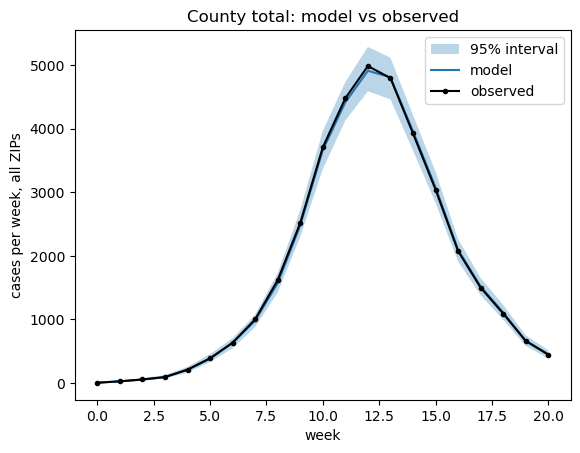

In [42]:
# Simulate weekly case counts from the fitted model, using a random 300 of the posterior draws
chosen = rng.choice(n_samples, size=min(300, n_samples), replace=False)
expected_cases = agents_in_zip[None, :, None] * np.exp(
    alpha_draws[chosen, None, None] + u_draws[chosen][:, zips_with_data, None] + v_draws[chosen, None, :])
k = dispersion_draws[chosen][:, None, None]
cases_simulated = rng.poisson(rng.gamma(k, expected_cases / k))              # (draws, ZIPs, weeks)

low, high = np.percentile(cases_simulated, [2.5, 97.5], axis=0)
print(f"95% interval covers {((cases_observed >= low) & (cases_observed <= high)).mean():.1%} of observed ZIP-week counts (aim: about 95%)")

total_low, total_mid, total_high = np.percentile(cases_simulated.sum(1), [2.5, 50, 97.5], axis=0)
plt.fill_between(range(n_weeks), total_low, total_high, alpha=0.3, label="95% interval")
plt.plot(total_mid, label="model"); plt.plot(cases_observed.sum(0), "k.-", ms=6, label="observed")
plt.xlabel("week"); plt.ylabel("cases per week, all ZIPs"); plt.legend(); plt.title("County total: model vs observed")
plt.show()

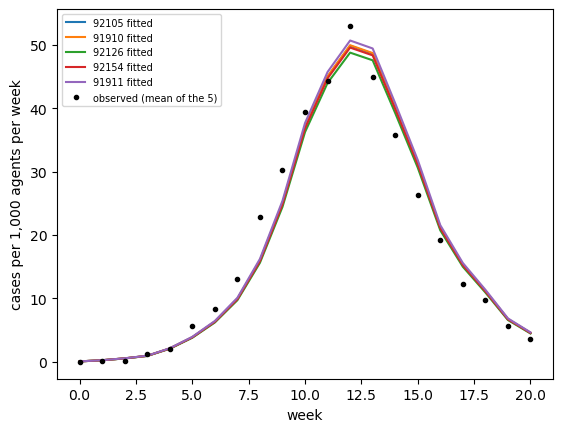

In [43]:
# Posterior rate per ZIP and week, for every ZIP (including ones with 0 agents, whose u comes from their neighbours)
rate_draws = np.exp(alpha_draws[:, None, None] + u_draws[:, :, None] + v_draws[:, None, :])    # (draws, all ZIPs, weeks)
rate_mean = rate_draws.mean(axis=0)                                  # (ZIPs, weeks): posterior mean rate per agent per week
rate_low, rate_high = np.percentile(rate_draws, [2.5, 97.5], axis=0)

# Compare to the observed rate in the 5 biggest ZIPs
big = np.argsort(N)[-5:]
for i in big:
    plt.plot(rate_mean[i] * 1000, label=f"{zips.loc[i, 'zip']} fitted")
plt.plot((cases_weekly_all[big] / N[big][:, None]).mean(0) * 1000, "k.", label="observed (mean of the 5)")
plt.xlabel("week"); plt.ylabel("cases per 1,000 agents per week"); plt.legend(fontsize=7); plt.show()

### Forecast ahead

In [44]:
n_hold = 4
n_train = n_weeks - n_hold
cases_train = cases_observed[:, :n_train]               # weeks the model is allowed to see
cases_test = cases_observed[:, n_train:]                # last 4 weeks, hidden from the model
log_avg_rate_train = float(np.log(cases_train.sum() / (agents_in_zip.sum() * n_train)))
print(f"training weeks: {n_train}   held-out weeks: {n_hold}")

with pm.Model() as model_train:
    alpha = pm.Normal("alpha", log_avg_rate_train, 2.0)                       # intercept: average log weekly rate

    sigma_u = pm.HalfNormal("sigma_u", 1.0)                                   # sd of the spatial effect across ZIPs
    rho = pm.Beta("rho", 1, 1)                                                # share of u that is spatially smooth
    u_smooth = pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips)          # smooth part
    pm.Potential("icar", -0.5 * pt.sum((u_smooth[neighbour_a] - u_smooth[neighbour_b]) ** 2))
    u_independent = pm.Normal("u_independent", 0, 1, shape=n_zips)            # noise part
    u = pm.Deterministic("u", sigma_u * (pt.sqrt(rho / bym2_scale) * u_smooth + pt.sqrt(1 - rho) * u_independent))

    sigma_v = pm.HalfNormal("sigma_v", 1.0)                                   # sd of one week's change in log-rate
    weekly_steps = pm.Normal("weekly_steps", 0, 1, shape=n_train)             # TRAINING weeks only
    v_walk = sigma_v * pt.cumsum(weekly_steps)
    v = pm.Deterministic("v", v_walk - v_walk.mean())

    eta = alpha + u[zips_with_data][:, None] + v[None, :]
    dispersion = pm.Exponential("dispersion", 0.1)
    pm.NegativeBinomial("cases", mu=pt.exp(eta + np.log(agents_in_zip)[:, None]),
                        alpha=dispersion, observed=cases_train)

    idata_train = pm.sample(draws=3000, tune=2000, chains=4, target_accept=0.95, random_seed=1,
                            nuts_sampler="nutpie", progressbar=False)

print(az.summary(idata_train, var_names=["alpha", "sigma_u", "rho", "sigma_v", "dispersion"]))
print("divergences:", int(idata_train.sample_stats["diverging"].sum()))


training weeks: 17   held-out weeks: 4
              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
alpha       -4.997  0.029  -5.050   -4.942      0.001    0.000    2060.0   
sigma_u      0.068  0.014   0.042    0.095      0.000    0.000    2347.0   
rho          0.840  0.143   0.568    1.000      0.003    0.002    2166.0   
sigma_v      0.614  0.134   0.390    0.837      0.015    0.014      73.0   
dispersion  28.727  2.922  23.502   34.331      0.026    0.027   12982.0   

            ess_tail  r_hat  
alpha         4135.0   1.01  
sigma_u       3406.0   1.00  
rho           3744.0   1.00  
sigma_v        188.0   1.06  
dispersion    9391.0   1.00  
divergences: 0


forecast 95% interval covers 100.0% of hidden ZIP-week counts
mean absolute error per ZIP-week:  model 21.66   naive 10.67
county total, hidden weeks:
  week 17: observed  1501   forecast    2108  (95%: 592 to 7229)
  week 18: observed  1092   forecast    2120  (95%: 376 to 10263)
  week 19: observed   663   forecast    2064  (95%: 220 to 15812)
  week 20: observed   447   forecast    2140  (95%: 195 to 22616)


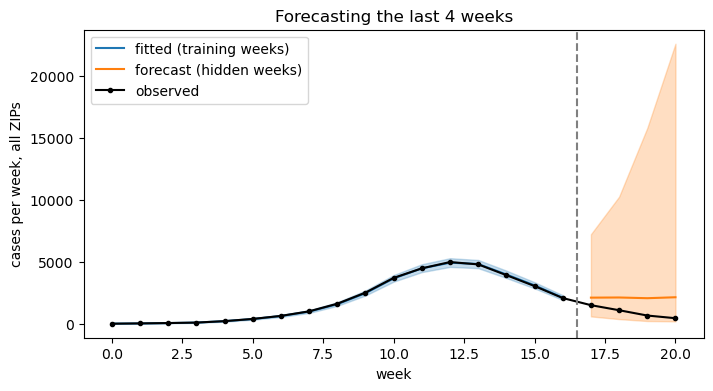

In [45]:
rng = np.random.default_rng(0)
post = idata_train.posterior
n_s = post.sizes["chain"] * post.sizes["draw"]
alpha_d = post["alpha"].values.reshape(n_s)
u_d = post["u"].values.reshape(n_s, n_zips)
v_d = post["v"].values.reshape(n_s, n_train)
sigma_v_d = post["sigma_v"].values.reshape(n_s)
disp_d = post["dispersion"].values.reshape(n_s)

pick = rng.choice(n_s, size=1000, replace=False)

# Future weekly effect: last fitted value + running total of new random steps (one chain of steps per draw)
new_steps = rng.normal(size=(len(pick), n_hold)) * sigma_v_d[pick][:, None]
v_future = v_d[pick, -1][:, None] + np.cumsum(new_steps, axis=1)              # (draws, 4 weeks)

def simulate_cases(v_part):
    """Expected cases from alpha + u + v, then add NegBin noise. v_part is (draws, weeks)."""
    mu = agents_in_zip[None, :, None] * np.exp(
        alpha_d[pick, None, None] + u_d[pick][:, zips_with_data, None] + v_part[:, None, :])
    k = disp_d[pick][:, None, None]
    return mu, rng.poisson(rng.gamma(k, mu / k))

mu_future, sim_future = simulate_cases(v_future)              # forecast of the hidden weeks
mu_fit, sim_fit = simulate_cases(v_d[pick])                   # fitted values for the training weeks

# ---- Scores on the hidden weeks ----
lo, hi = np.percentile(sim_future, [2.5, 97.5], axis=0)
print(f"forecast 95% interval covers {((cases_test >= lo) & (cases_test <= hi)).mean():.1%} of hidden ZIP-week counts")

model_pred = mu_future.mean(axis=0)                            # posterior mean forecast, (ZIPs, 4)
naive_pred = np.repeat(cases_train[:, -1:], n_hold, axis=1)    # naive baseline: "same as the last training week"
print(f"mean absolute error per ZIP-week:  model {np.abs(model_pred - cases_test).mean():.2f}   naive {np.abs(naive_pred - cases_test).mean():.2f}")

tot_lo, tot_mid, tot_hi = np.percentile(sim_future.sum(1), [2.5, 50, 97.5], axis=0)
print("county total, hidden weeks:")
for w in range(n_hold):
    print(f"  week {n_train + w}: observed {cases_test.sum(0)[w]:5d}   forecast {tot_mid[w]:7.0f}  (95%: {tot_lo[w]:.0f} to {tot_hi[w]:.0f})")

# ---- Plot ----
fit_lo, fit_mid, fit_hi = np.percentile(sim_fit.sum(1), [2.5, 50, 97.5], axis=0)
plt.figure(figsize=(8, 4))
plt.fill_between(range(n_train), fit_lo, fit_hi, alpha=0.25, color="tab:blue")
plt.plot(range(n_train), fit_mid, color="tab:blue", label="fitted (training weeks)")
plt.fill_between(range(n_train, n_weeks), tot_lo, tot_hi, alpha=0.25, color="tab:orange")
plt.plot(range(n_train, n_weeks), tot_mid, color="tab:orange", label="forecast (hidden weeks)")
plt.plot(range(n_weeks), cases_observed.sum(0), "k.-", label="observed")
plt.axvline(n_train - 0.5, color="grey", ls="--")
plt.xlabel("week"); plt.ylabel("cases per week, all ZIPs"); plt.legend(); plt.title("Forecasting the last 4 weeks")
plt.show()

## Additional Plots

### Viewing neighbours

In [63]:
def community_neighbours(name):
    members = np.flatnonzero(zips["community"] == name)             # row numbers of every ZIP in this community
    touches_any = adjacency[members].any(axis=0)                    # True for any ZIP that touches at least one member
    touching = zips.loc[touches_any, "community"]                   # community names of those ZIPs
    return sorted(set(touching) - {name})                           # drop the community itself, remove repeats

In [71]:
def plot_neighbours(name):
    is_member = (zips["community"] == name).to_numpy()              # True for ZIPs in this community
    touches_member = adjacency[is_member].any(axis=0)               # True for any ZIP touching at least one member
    is_neighbour = touches_member & ~is_member                      # touching ZIPs, excluding the community itself

    ax = zips.plot(color="lightgrey", edgecolor="white", figsize=(6, 6))   # all ZIPs in grey
    zips[is_neighbour].plot(ax=ax, color="orange", edgecolor="white")      # neighbours in orange
    zips[is_member].plot(ax=ax, color="red", edgecolor="white")            # the community in red
    ax.set_title(f"{name} (red) and the ZIPs it touches (orange)")
    ax.set_axis_off()
    plt.show()

San Diego touches: ['Bonita', 'Chula Vista', 'Coronado', 'Del Mar', 'Dulzura', 'El Cajon', 'Escondido', 'Imperial Beach', 'La Jolla', 'La Mesa', 'Lemon Grove', 'National City', 'Poway', 'Rancho Santa Fe', 'San Ysidro', 'Santee', 'Spring Valley']


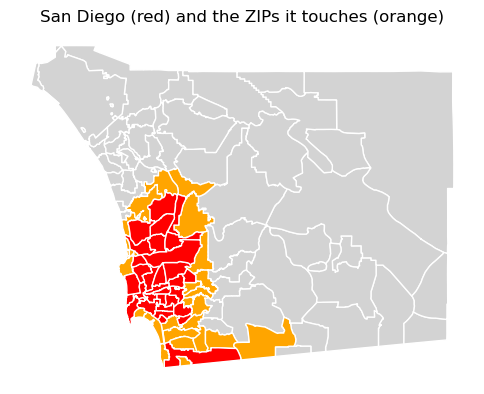

In [72]:
name = "San Diego"
print("San Diego touches:", community_neighbours(name))
plot_neighbours(name)

La Jolla touches:    ['San Diego']


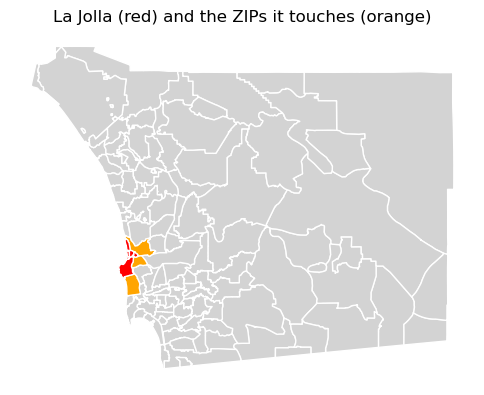

In [73]:
name = 'La Jolla'
print("La Jolla touches:   ", community_neighbours(name))
plot_neighbours(name)

Alpine touches:    ['Campo', 'Descanso', 'Dulzura', 'El Cajon', 'Jamul', 'Julian', 'Lakeside', 'Pine Valley', 'Potrero', 'Ramona']


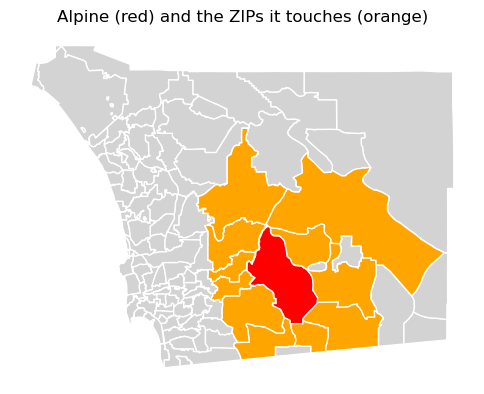

In [74]:
name = 'Alpine'
print("Alpine touches:   ", community_neighbours(name))
plot_neighbours(name)

In [1]:
name = 'Poway'
print("Poway touches:   ", community_neighbours(name))
plot_neighbours(name)

NameError: name 'community_neighbours' is not defined

### ii. Define islands

In [51]:
# Join any islands to the main map by linking them to the nearest ZIP (by centroid)
cent = np.column_stack([zips.geometry.centroid.x, zips.geometry.centroid.y])
n_comp, lab = connected_components(sp.csr_matrix(A), directed=False)
print("separate pieces before joining:", n_comp)
while n_comp > 1:
    print(n_comp)
    main = lab == np.argmax(np.bincount(lab))
    d = cdist(cent[~main], cent[main])
    i, j = np.unravel_index(d.argmin(), d.shape)
    a, b = np.flatnonzero(~main)[i], np.flatnonzero(main)[j]
    print(f"linking {zips.loc[a, 'community']} -> {zips.loc[b, 'community']}")
    A[a, b] = A[b, a] = True
    n_comp, lab = connected_components(sp.csr_matrix(A), directed=False)

separate pieces before joining: 1


/tmp/ipykernel_157395/474021733.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  cent = np.column_stack([zips.geometry.centroid.x, zips.geometry.centroid.y])


In [52]:
# Which ZIPs have data? (ZIPs with 0 agents stay in the map but have no likelihood)
has_data = N > 0
obs_idx = np.flatnonzero(has_data)
print(f"ZIPs total: {len(zips)}   with agents: {has_data.sum()}   with 0 agents: {(~has_data).sum()}")


ZIPs total: 113   with agents: 112   with 0 agents: 1


### Data -- Zips with data

In [53]:
Nm = N[obs_idx].astype(float)          # offset N_i, only for ZIPs with agents
Y = cases[obs_idx]                     # observed cases, only for ZIPs with agents
I, T = len(zips), cases.shape[1]       # I = ALL ZIPs (the spatial effect covers every ZIP)
ei, ej = np.where(np.triu(A, 1))
print(f"{len(ei)} neighbour pairs, average neighbours {A.sum(1).mean():.1f}")

299 neighbour pairs, average neighbours 5.3


In [ ]:


# Neighbours: two ZIPs are neighbours if their outlines touch (tiny buffer closes hairline gaps)
zip_shapes = zips.geometry.buffer(1e-6)
shape_index = zip_shapes.sindex
adjacency = np.zeros((len(zips), len(zips)), dtype=bool)
for i, shape in enumerate(zip_shapes):
    for j in shape_index.query(shape, predicate="intersects"):
        if j != i:
            adjacency[i, j] = True
adjacency = adjacency | adjacency.T

# Join any islands to the main map by linking them to the nearest ZIP (by centroid)
centroids = np.column_stack([zips.geometry.centroid.x, zips.geometry.centroid.y])
n_pieces, piece_of_zip = connected_components(sp.csr_matrix(adjacency), directed=False)
print("separate pieces before joining:", n_pieces)
while n_pieces > 1:
    in_main_piece = piece_of_zip == np.argmax(np.bincount(piece_of_zip))
    distances = cdist(centroids[~in_main_piece], centroids[in_main_piece])
    row, col = np.unravel_index(distances.argmin(), distances.shape)
    island_zip = np.flatnonzero(~in_main_piece)[row]
    main_zip = np.flatnonzero(in_main_piece)[col]
    print(f"linking {zips.loc[island_zip, 'community']} -> {zips.loc[main_zip, 'community']}")
    adjacency[island_zip, main_zip] = adjacency[main_zip, island_zip] = True
    n_pieces, piece_of_zip = connected_components(sp.csr_matrix(adjacency), directed=False)

# Which ZIPs have data? (ZIPs with 0 agents stay in the map but have no likelihood)
zip_has_agents = N > 0
zips_with_data = np.flatnonzero(zip_has_agents)
print(f"ZIPs total: {len(zips)}   with agents: {zip_has_agents.sum()}   with 0 agents: {(~zip_has_agents).sum()}")

agents_in_zip = N[zips_with_data].astype(float)     # offset N_i, only ZIPs with agents
cases_observed = cases[zips_with_data]              # observed cases y_it, only ZIPs with agents
n_zips = len(zips)                                  # ALL ZIPs (the spatial effect covers every ZIP)
n_days = cases.shape[1]

# Each touching pair of ZIPs listed once: ZIP neighbour_a[k] touches ZIP neighbour_b[k]
neighbour_a, neighbour_b = np.where(np.triu(adjacency, 1))
print(f"{len(neighbour_a)} neighbour pairs, average neighbours per ZIP {adjacency.sum(1).mean():.1f}")

# BYM2 scaling factor (makes the smooth part have variance about 1, so rho is interpretable)
icar_precision = np.diag(adjacency.sum(1)) - adjacency.astype(float)
bym2_scale = float(np.exp(np.mean(np.log(np.diag(np.linalg.pinv(icar_precision))))))
print("BYM2 scaling factor =", round(bym2_scale, 3))